In [2]:
import awkward as ak
import uproot
import pandas as pd
import numpy as np

In [70]:
import vector as vec
import matplotlib.pyplot as plt

can just make a jpsi in the miniaod
problems come specifically from flat tables

In [168]:
newmu = uproot.open('muonTest2.root:Events')
newmu.keys()

['EventAuxiliary',
 'EventProductProvenance',
 'EventSelections',
 'BranchListIndexes',
 'patJets_slimmedJets__PAT.',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.present',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fX',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fY',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fZ',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_slimmedJets__PAT./patJ

In [172]:
mu_data = newmu.arrays(['int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj','nanoaodFlatTable_muonTable__RECLUSTER./nanoaodFlatTable_muonTable__RECLUSTER.obj/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_.name','nanoaodFlatTable_muonTable__RECLUSTER./nanoaodFlatTable_muonTable__RECLUSTER.obj/nanoaodFlatTable_muonTable__RECLUSTER.obj.floats_'])

mu_data

<Array [{...}, {...}, {...}, ..., {...}, {...}] type='1000 * {"int_eventIdP...'>

In [173]:
mu_df = ak.to_dataframe(mu_data)
mu_df.iloc[0:20]

int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj  \
entry subentry                                                                                 
0     0                                                 522613774                              
      1                                                 522613774                              
      2                                                 522613774                              
      3                                                 522613774                              
      4                                                 522613774                              
      5                                                 522613774                              
1     0                                                 522570559                              
      1                                                 522570559                              
      2                                                 522570559                              
      3                                                 522570559                              
      4                                                 522570559                              
      5                                                 522570559                              
2     0                                                 523131784                              
      1                                                 523131784                              
      2                                                 523131784                              
      3                                                 523131784                              
      4                                                 523131784                              
      5                                                 523131784                              
3     0                                                 521783914                              
      1                                                 521783914                              

               nanoaodFlatTable_muonTable__RECLUSTER./nanoaodFlatTable_muonTable__RECLUSTER.obj/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_.name  \
entry subentry                                                                                                                                                                                               
0     0                                                    charge                                                                                                                                            
      1                                                       eta                                                                                                                                            
      2                                                  isGlobal                                                                                                                                            
      3                                                      mass                                                                                                                                            
      4                                                       phi                                                                                                                                            
      5                                                        pt                                                                                                                                            
1     0                                                    charge                                                                                                                                            
      1                                          

miniAOD files are... to nobody's surprise... miniAOD files. I cannot work with them.

In [175]:
file = uproot.open('muonTest2.root:Events')
file.keys()

['EventAuxiliary',
 'EventProductProvenance',
 'EventSelections',
 'BranchListIndexes',
 'patJets_slimmedJets__PAT.',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.present',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fX',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fY',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fZ',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_slimmedJets__PAT./patJ

,int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj
entry,
0,281976
1,281976
2,281976
3,281976
4,281976
...,...
140135,281976
140136,281976
140137,281976


In [145]:
muons =file.arrays(['nanoaodFlatTable_muonTable__RECLUSTER./nanoaodFlatTable_muonTable__RECLUSTER.obj/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_.firstIndex',
                    'nanoaodFlatTable_muonTable__RECLUSTER./nanoaodFlatTable_muonTable__RECLUSTER.obj/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_.name',
                    'nanoaodFlatTable_muonTable__RECLUSTER./nanoaodFlatTable_muonTable__RECLUSTER.obj/nanoaodFlatTable_muonTable__RECLUSTER.obj.floats_'])
muon_df = ak.to_dataframe(muons)
muon_df.rename(inplace=True, columns ={'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj':'run',
                    'int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj':'event',
                    'nanoaodFlatTable_muonTable__RECLUSTER./nanoaodFlatTable_muonTable__RECLUSTER.obj/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_.name':'col_name',
                    'nanoaodFlatTable_muonTable__RECLUSTER./nanoaodFlatTable_muonTable__RECLUSTER.obj/nanoaodFlatTable_muonTable__RECLUSTER.obj.floats_':'col_val'})
muon_df
# mu_charge = muon_df.loc[muon_df.col_name =='charge']
# mu_charge.head()

nanoaodFlatTable_muonTable__RECLUSTER./nanoaodFlatTable_muonTable__RECLUSTER.obj/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_/nanoaodFlatTable_muonTable__RECLUSTER.obj.columns_.firstIndex  \
entry  subentry                                                                                                                                                                                                      
0      0                                                         0                                                                                                                                                   
       1                                                         0                                                                                                                                                   
       2                                                         6                                                                                                                                                   
       3                                                        12                                                                                                                                                   
       4                                                        18                                                                                                                                                   
...                                                            ...                                                                                                                                                   
140139 0                                                         0                                                                                                                                                   
       1                                                         0                                                                                                                                                   
       2                                                         2                                                                                                                                                   
       3                                                         4                                                                                                                                                   
       4                                                         6                                                                                                                                                   

                col_name   col_val  
entry  subentry                     
0      0          charge -1.075195  
       1             eta -0.957031  
       2            mass -1.897461  
       3             phi  1.569336  
       4              pt -2.201172  
...                  ...       ...  
140139 0          charge -1.352539  
       1             eta -1.882812  
       2            mass  0.105713  
       3             phi  0.105713  
       4              pt -0.361328  

[700535 rows x 3 columns]

In [176]:
btags = file.arrays(['int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
                     'int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
                     'nanoaodFlatTable_btagTable__RECLUSTER./nanoaodFlatTable_btagTable__RECLUSTER.obj/nanoaodFlatTable_btagTable__RECLUSTER.obj.floats_',
                     'nanoaodFlatTable_btagTable__RECLUSTER./nanoaodFlatTable_btagTable__RECLUSTER.obj/nanoaodFlatTable_btagTable__RECLUSTER.obj.columns_/nanoaodFlatTable_btagTable__RECLUSTER.obj.columns_.name'])
btag_df = ak.to_dataframe(btags)
btag_df.rename(columns={'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj':'run',
                        'int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj':'event',
                        'nanoaodFlatTable_btagTable__RECLUSTER./nanoaodFlatTable_btagTable__RECLUSTER.obj/nanoaodFlatTable_btagTable__RECLUSTER.obj.floats_':'tag_val',
                        'nanoaodFlatTable_btagTable__RECLUSTER./nanoaodFlatTable_btagTable__RECLUSTER.obj/nanoaodFlatTable_btagTable__RECLUSTER.obj.columns_/nanoaodFlatTable_btagTable__RECLUSTER.obj.columns_.name':'tag_name'}, inplace=True)
btag_df

run      event   tag_val        tag_name
entry subentry                                             
0     0         281976  522613774  0.002598   btagDeepFlavB
      1         281976  522613774  0.006550   deepCSV_probb
      2         281976  522613774  0.046051  deepCSV_probbb
      3         281976  522613774  0.033722   deepCSV_probc
1     0         281976  522570559  0.006020   btagDeepFlavB
...                ...        ...       ...             ...
998   3         281976  521800291  0.008026   deepCSV_probc
999   0         281976  521681148  0.060913   btagDeepFlavB
      1         281976  521681148  0.032257   deepCSV_probb
      2         281976  521681148  0.021851  deepCSV_probbb
      3         281976  521681148  0.026505   deepCSV_probc

[4000 rows x 4 columns]

In [47]:
file = uproot.open('nanoAOD_reclustered_AK1_full.root:Events')
file.keys()

['EventAuxiliary',
 'EventProductProvenance',
 'EventSelections',
 'BranchListIndexes',
 'patJets_slimmedJets__PAT.',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.present',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fX',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fY',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fZ',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_slimmedJets__PAT./patJ

In [177]:
akdf = file.arrays(['int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
             'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
              'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.jetCharge_',
 'patJets_updatedJetsWithUserData__RECLUSTER./patJets_updatedJetsWithUserData__RECLUSTER.obj/patJets_updatedJetsWithUserData__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_updatedJetsWithUserData__RECLUSTER./patJets_updatedJetsWithUserData__RECLUSTER.obj/patJets_updatedJetsWithUserData__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_updatedJetsWithUserData__RECLUSTER./patJets_updatedJetsWithUserData__RECLUSTER.obj/patJets_updatedJetsWithUserData__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_updatedJetsWithUserData__RECLUSTER./patJets_updatedJetsWithUserData__RECLUSTER.obj/patJets_updatedJetsWithUserData__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM',
 'patJets_updatedJetsWithUserData__RECLUSTER./patJets_updatedJetsWithUserData__RECLUSTER.obj/patJets_updatedJetsWithUserData__RECLUSTER.obj.jetCharge_',
  'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fM',
  'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.jetCharge_'])
ak1_pd = ak.to_dataframe(akdf)

In [178]:
ak1_pd

int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj  \
entry subentry                                                                                 
0     0                                                 522613774                              
      1                                                 522613774                              
      2                                                 522613774                              
      3                                                 522613774                              
      4                                                 522613774                              
...                                                           ...                              
999   8                                                 521681148                              
      9                                                 521681148                              
      10                                                521681148                              
      11                                                521681148                              
      12                                                521681148                              

                int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj  \
entry subentry                                                                             
0     0                                                    281976                          
      1                                                    281976                          
      2                                                    281976                          
      3                                                    281976                          
      4                                                    281976                          
...                                                           ...                          
999   8                                                    281976                          
      9                                                    281976                          
      10                                                   281976                          
      11                                                   281976                          
      12                                                   281976                          

                patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt  \
entry subentry                                                                                                                                               
0     0                                                 30.994141                                                                                            
      1                                                 12.156250                                                                                            
      2                                                  9.129927                                                                                            
      3                                                  8.187691                                                                                            
      4                                                  6.101562                                                                                            
...                                                           ...                                                                                            
999   8                                                  4.277344                                                                                            
      9                                                  4.175781                                                                                   

In [64]:
ak1_pd.rename(columns ={'int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj':'event',
             'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj':'run',
              'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt':'ak1_pt',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta':'ak1_eta',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi':'ak1_phi',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM':'ak1_mass',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.jetCharge_':'ak1_charge',
 'patJets_updatedJetsWithUserData__RECLUSTER./patJets_updatedJetsWithUserData__RECLUSTER.obj/patJets_updatedJetsWithUserData__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt':'btag_pt',
 'patJets_updatedJetsWithUserData__RECLUSTER./patJets_updatedJetsWithUserData__RECLUSTER.obj/patJets_updatedJetsWithUserData__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta':'btag_eta',
 'patJets_updatedJetsWithUserData__RECLUSTER./patJets_updatedJetsWithUserData__RECLUSTER.obj/patJets_updatedJetsWithUserData__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi':'btag_phi',
 'patJets_updatedJetsWithUserData__RECLUSTER./patJets_updatedJetsWithUserData__RECLUSTER.obj/patJets_updatedJetsWithUserData__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM':'btag_mass',
 'patJets_updatedJetsWithUserData__RECLUSTER./patJets_updatedJetsWithUserData__RECLUSTER.obj/patJets_updatedJetsWithUserData__RECLUSTER.obj.jetCharge_':'btag_charge',
  'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt':'ak4_pt',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta':'ak4_eta',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi':'ak4_phi',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fM':'ak4_mass',
  'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.jetCharge_':'ak4_charge'}, inplace=True)

charge is the wrong type of charge

In [65]:
ak1_pd.head()

event     run    ak1_pt   ak1_eta   ak1_phi      ak1_mass  \
entry subentry                                                                  
0     0         521846398  281976  6.398438 -3.434614  3.055854 -1.907349e-06   
      1         521846398  281976  6.210416 -2.802710  0.248688  7.977068e-02   
      2         521846398  281976  6.148438 -3.436811  0.610076  1.907349e-06   
      3         521846398  281976  5.851562 -2.757103  1.221230  6.743496e-07   
      4         521846398  281976  4.371094 -0.519120 -0.521795  1.395264e-01   

                ak1_charge    btag_pt  btag_eta  btag_phi  btag_mass  \
entry subentry                                                         
0     0                0.0  21.287712 -3.437167  3.054484   5.071896   
      1                0.0  16.926594 -3.512425  0.586143   3.849146   
      2                0.0  13.577738 -0.742079 -0.432655   3.626722   
      3                0.0  13.526744 -3.577233 -1.321024   3.429222   
      4                0.0  12.149314 -2.883712  0.255492   1.861137   

                btag_charge     ak4_pt   ak4_eta   ak4_phi  ak4_mass  \
entry subentry                                                         
0     0            0.000000  21.287710 -3.437167  3.054484  5.071896   
      1            0.000000  16.926594 -3.512425  0.586143  3.849146   
      2            0.308013  13.577738 -0.742079 -0.432655  3.626722   
      3            0.000000  13.526744 -3.577233 -1.321024  3.429222   
      4            0.000000  12.149314 -2.883712  0.255492  1.861137   

                ak4_charge  
entry subentry              
0     0           0.000000  
      1           0.000000  
      2           0.308013  
      3           0.000000  
      4           0.000000

In [80]:
ak1_pd = ak1_pd.loc[ak1_pd.ak1_mass >1.5]

In [81]:
ak1_vec = vec.array({'pt':ak1_pd.ak1_pt,'eta':ak1_pd.ak1_eta,'phi':ak1_pd.ak1_phi,'mass':ak1_pd.ak1_mass})
ak1_energy = ak1_vec.e
ak1_energy

array([ 39.71161606,  64.56052634, 213.07445488, ..., 710.19971755,
       749.6038151 , 111.98652548], shape=(6440,))

In [82]:
ak4_vec = vec.array({'pt':ak1_pd.ak4_pt, 'eta':ak1_pd.ak4_eta,'phi':ak1_pd.ak4_phi,'mass':ak1_pd.ak4_mass})
ak4_energy = ak4_vec.e
ak4_energy

array([  79.59371221,   81.60278033,  307.5496921 , ...,  921.57588708,
       1135.02694282,  277.97077419], shape=(6440,))

In [83]:
energy_ratio = ak1_energy/ak4_energy

(array([3.933e+03, 1.569e+03, 4.720e+02, 2.360e+02, 1.010e+02, 5.500e+01,
        3.000e+01, 1.300e+01, 8.000e+00, 8.000e+00, 3.000e+00, 3.000e+00,
        3.000e+00, 0.000e+00, 3.000e+00, 1.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([  11.8002398 ,  178.83374039,  345.86724098,  512.90074157,
         679.93424216,  846.96774275, 1014.00124334, 1181.03474393,
        1348.06824451, 1515.1017451 , 1682.13524569, 1849.16874628,
        2016.20224687, 2183.23574746, 2350.26924805, 2517.30274864,
        2684.33624923, 2851.36974982, 3018.40325041, 3185.436751  ,
        3352.47025159]),
 <BarContainer object of 20 artists>)

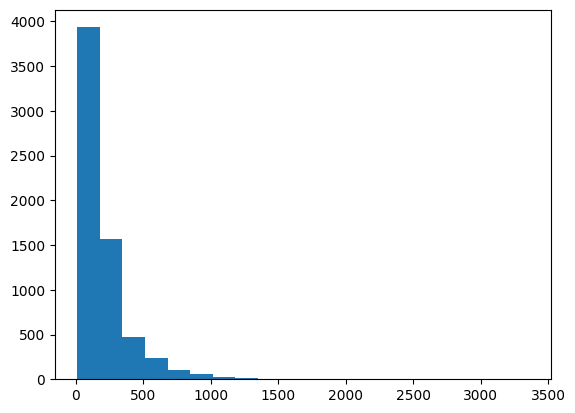

In [90]:
plt.hist(ak4_energy, bins = 20)

In [ ]:
ak1_pd.insert(loc=0, column = 'e_ratio', value=energy_ratio)

ValueError: cannot insert e_ratio, already exists

In [93]:
ak1_pd.head()

e_ratio      event     run      ak1_pt   ak1_eta   ak1_phi  \
entry subentry                                                                
43    0         0.498929  521673324  281976   37.843716 -0.310219  1.953685   
52    0         0.791156  523225600  281976   53.936913 -0.616247  0.977264   
69    0         0.692813  522947047  281976   58.230965 -1.971090  2.725086   
83    0         0.517984  522660488  281976  100.741562  0.575545 -2.966124   
      1         0.318532  522660488  281976   57.598351  1.005392  0.244560   

                ak1_mass  ak1_charge     btag_pt  btag_eta  btag_phi  \
entry subentry                                                         
43    0         1.600941         0.0   72.682693 -0.385794  2.002483   
52    0         2.635731         0.0   67.145432 -0.634662  0.962378   
69    0         2.363806         0.0   84.892960 -1.960250  2.733319   
83    0         5.026573         0.0  190.178711  0.605624 -3.006094   
      1         1.623364         0.0  180.527069  1.005965  0.248893   

                btag_mass  btag_charge      ak4_pt   ak4_eta   ak4_phi  \
entry subentry                                                           
43    0         15.044004     0.256035   72.682693 -0.385794  2.002483   
52    0          8.785727    -0.215071   67.145432 -0.634662  0.962378   
69    0          9.774922    -0.651749   84.892960 -1.960250  2.733319   
83    0         27.540895    -0.090032  190.178711  0.605624 -3.006094   
      1         14.673553     0.430038  180.527069  1.005965  0.248893   

                 ak4_mass  ak4_charge  
entry subentry                         
43    0         15.044004    0.256035  
52    0          8.785727   -0.215071  
69    0          9.774922   -0.651749  
83    0         27.540895   -0.090032  
      1         14.673553    0.430038

In [94]:
e_df = ak1_pd.loc[ak1_pd.e_ratio>0.75]

(array([ 37.,  96., 147., 162., 198., 278., 386., 518., 613., 752., 767.,
        749., 621., 426., 261., 113.,  52.,  29.,  18.,  18.]),
 array([0.   , 0.055, 0.11 , 0.165, 0.22 , 0.275, 0.33 , 0.385, 0.44 ,
        0.495, 0.55 , 0.605, 0.66 , 0.715, 0.77 , 0.825, 0.88 , 0.935,
        0.99 , 1.045, 1.1  ]),
 <BarContainer object of 20 artists>)

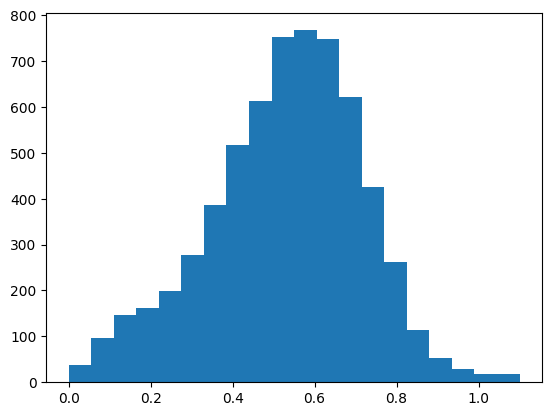

In [87]:
plt.hist(energy_ratio, bins = 20, range = (0,1.1))

(array([ 143.,  346.,  697., 1086., 1160., 1121.,  955.,  571.,  254.,
         107.]),
 array([-2.89700389, -2.30092638, -1.70484886, -1.10877135, -0.51269383,
         0.08338368,  0.67946119,  1.27553871,  1.87161622,  2.46769373,
         3.06377125]),
 <BarContainer object of 10 artists>)

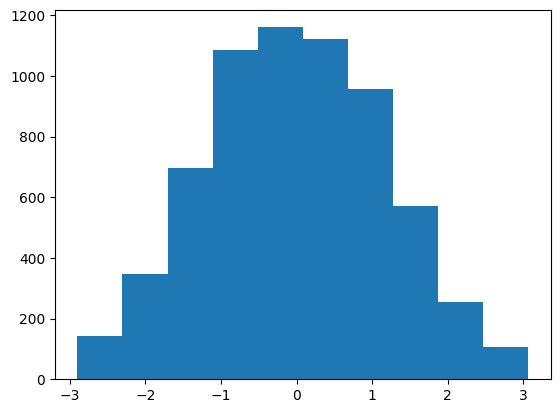

In [98]:
plt.hist(ak1_pd.ak1_eta)

(array([ 49.,  65.,  85., 116., 127., 110., 121.,  68.,  52.,  38.]),
 array([-2.87026262, -2.27685924, -1.68345585, -1.09005246, -0.49664907,
         0.09675431,  0.6901577 ,  1.28356109,  1.87696447,  2.47036786,
         3.06377125]),
 <BarContainer object of 10 artists>)

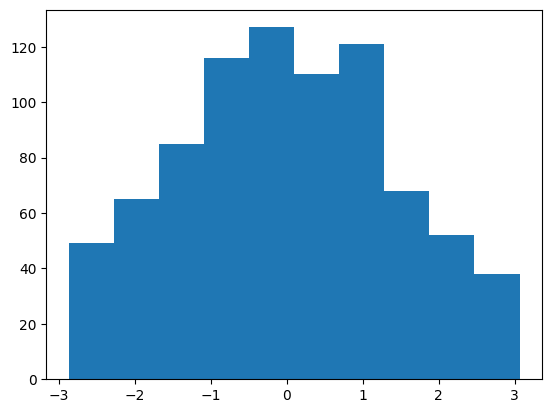

In [99]:
plt.hist(e_df.ak1_eta)

keep energy ratio greater than 0.75
want the jet dists to match

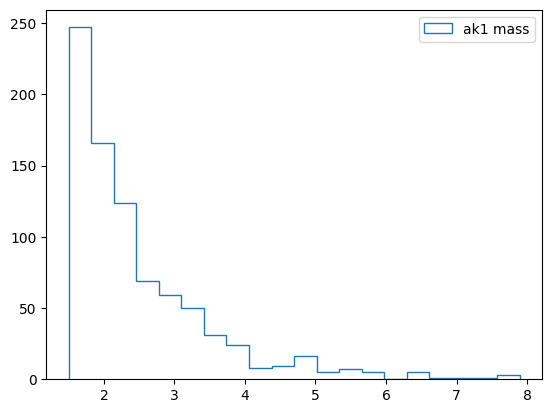

In [97]:
plt.hist(e_df.ak1_mass, label ='ak1 mass', histtype ='step', bins = 20)
#plt.hist(e_df.ak4_mass, label = 'ak4 mass', histtype = 'step')
plt.legend()

spike around 5 is likely b jets 